*[cell 0]*

# LVL_1 Sweep Report — T2 calibration

Calibration of the LVL_1 knobs on the sweep written by `launch_LV1_sweep_random.py` (T2 only). The report reads the
sweep folder only (`SWEEP_DIR`, `[cell 1]`; its `_provenance.json` is checked by `sweep_provenance.py`). The one file
it may write there is `_script_lvl1.py`, the byte copy of the `lvl1.py` the sweep ran: only when the copy is missing
and `lvl1.py` still has the sweep's fingerprint.

**Conditions.** The manuscript calls the two conditions cohorts: T2 = Cohort A (CA), T3 = Cohort B (CB). The code,
file names, exports and the final report keep T2 and T3; only `make_replication_figures.ipynb` prints CA and CB.

Sections:

0. **Quality filters and effect-size definition**
1. **Which knobs matter** (Tables 1.1–1.4: SS shares of `smoothing_window` and `pelt_jump` per detector; the knob values at each detector's best configuration)
2. **Main effect of each knob**: the mean effect size at each knob level (figure)
3. **The winner**, by effect size, with both significance rates beside it
4. **Best solution per method**: each detector at its own optimal configuration
6. **Interactions**: `pelt_jump` x `smoothing_window` (heatmap)
7. **Summary**: the winner under each criterion, and the selection

**Outputs** (in `LVL_OUTS`): `<sweep>_report_{knob_ss, selection_freq, best_per_detector}.csv` and
`<sweep>_selection.json`, the detector and knob values the LVL1 notebook's `LVL_1_CONFIG` must hold (its calibration
check reads the file), `LVL_1_CONFIG_full` (every key of the script copy's `LVL_1_CONFIG`, with those knob values)
and `script_copy` (the path of the script copy). H1 is tested in the LVL1 notebook on its handoff; the calibration figure is drawn by
`make_replication_figures.ipynb`.

In [1]:
# [cell 1]
# ===== INPUTS: set these before running =====
SWEEP_DIR = "_sweep_lvl1_T2"   # the sweep folder in SWEEPS_DIR (the launcher's --outdir), e.g. "_sweep_lvl1_T2"

import ast, sys, json, re
import numpy as np
import pandas as pd
from pathlib import Path

# ---- locations: everything is inside /home/sjsuss626/EMST_files/sjs_dissertation ----------------
LVL_OUTS   = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs")   # this report's tables
SWEEPS_DIR = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/sweeps")     # the sweep folders
CODE_DIR   = Path("/home/sjsuss626/EMST_files/sjs_dissertation/code/cpd_and_blk_rep_anaylsis")        # lvl1.py

_dwb, sys.dont_write_bytecode = sys.dont_write_bytecode, True   # as python -B: no __pycache__/
from sweep_provenance import read_sweep, pipeline_fingerprint, grid_fingerprint
sys.dont_write_bytecode = _dwb

if SWEEP_DIR is None:
    raise SystemExit("SWEEP_DIR is not set (top of this cell): the --outdir of launch_LV1_sweep_random.py")
# Only a directory whose _provenance.json matches its result files is accepted.
SWEEP_DIR = SWEEPS_DIR / SWEEP_DIR
SWEEP_PROV = read_sweep(SWEEP_DIR, r"cfg\d{6}",
                        {k: k for k in ("pipeline_fingerprint", "lvl0_input", "condition", "subsample", "seed")})
CFG_FILES = sorted(SWEEP_DIR.glob("cfg[0-9][0-9][0-9][0-9][0-9][0-9].csv"))
if not CFG_FILES:
    raise SystemExit(f"no cfg*.csv in {SWEEP_DIR}")
# Completeness: config ids are grid positions 0 .. N-1, and the cfg_ columns of the result files (the swept knobs in
# the launcher's order, then its fixed knobs) rebuild the grid whose hash is _provenance.json "grid". The sweep is read
# only when its cfg files (each with its sessions_ file) are that whole grid. Otherwise the configurations that failed
# or never ran are listed, with the launcher's errors/ files for the folder, and the report stops.
ERR_DIR = CODE_DIR / "errors"


def _cfg_value(s):
    """A cfg_ value as lvl1.py parsed it (the result files hold repr() of each value)."""
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return s


_files = {int(f.stem[-6:]): f for f in CFG_FILES}
_n = max(_files) + 1
_gaps = [f"cfg{i:06d}" for i in range(_n) if i not in _files]
_incomplete = [f.stem for f in _files.values() if not f.with_name(f"sessions_{f.name}").is_file()]
_recs = {}
for _i, _f in _files.items():
    _r = pd.read_csv(_f, nrows=1, keep_default_na=False, dtype=str)
    _recs[_i] = [(c[4:], _cfg_value(_r[c].iloc[0])) for c in _r.columns if c.startswith("cfg_")]
_grid_ok = False
if not _gaps and not _incomplete:
    for _k in range(len(_recs[0]) + 1):          # the first _k cfg_ columns are the swept knobs
        _fixed = dict(_recs[0][_k:])
        if all(dict(_recs[i][_k:]) == _fixed for i in _recs) and grid_fingerprint(
                [[v for _, v in _recs[i][:_k]] for i in range(_n)] + [_fixed]) == SWEEP_PROV["grid"]:
            _grid_ok = True
            print(f"{SWEEP_DIR.name}: {_n} configurations = the launcher's whole grid (hash {SWEEP_PROV['grid']}; swept "
                  f"{[k for k, _ in _recs[0][:_k]]}), each with its sessions_ file")
            break
if not _grid_ok:
    _errs = sorted(f.name for f in ERR_DIR.glob(f"{SWEEP_DIR.name}_*.err"))
    raise SystemExit(
        f"{SWEEP_DIR.name} is not the launcher's whole grid: {len(_files)} cfg files with ids up to {_n - 1}, which do not "
        f"rebuild the grid hashed in _provenance.json ({SWEEP_PROV['grid']}). Missing configurations: "
        f"{', '.join(_gaps) or 'none below the highest id'}"
        f"{'; without a sessions_ file: ' + ', '.join(_incomplete) if _incomplete else ''}; errors/ files: "
        f"{', '.join(_errs) or 'none'}. Re-run the launcher on this folder (it resumes) before reading it.")
# the launcher's pooled table must hold exactly the rows of every configuration file
_pooled = SWEEP_DIR / "sweep_results.csv"
if not _pooled.is_file():
    raise SystemExit(f"{_pooled.name} is missing in {SWEEP_DIR}: the launcher writes it when the sweep finishes")
_n_cfg = sum(len(pd.read_csv(f)) for f in CFG_FILES)
if len(pd.read_csv(_pooled)) != _n_cfg:
    raise SystemExit(f"{_pooled.name} has a different number of rows than the {len(CFG_FILES)} configuration files "
                     f"({_n_cfg}): re-run the launcher on {SWEEP_DIR.name} to pool them")
TAB_STEM = LVL_OUTS / f"{SWEEP_DIR.name}_report"
REPORT_TABLES = {}


def export(key, frame):
    """Write one table to LVL_OUTS as <sweep>_report_<key>.csv and show it."""
    REPORT_TABLES[key] = frame
    frame.to_csv(f"{TAB_STEM}_{key}.csv", index=False)
    display(frame)


print(f"sweep {SWEEP_DIR.name}: {len(CFG_FILES)} configurations, {_n_cfg:,} rows")
print(f"provenance: lvl1.py {SWEEP_PROV['pipeline_fingerprint']}, {SWEEP_PROV['lvl0_input']}, "
      f"condition={SWEEP_PROV['condition']}")
if pipeline_fingerprint(CODE_DIR / "lvl1.py") != SWEEP_PROV["pipeline_fingerprint"]:
    print("WARNING: lvl1.py has changed since this sweep ran; the sweep describes the OLD pipeline.")
# The script the sweep ran: its byte copy SWEEP_DIR/_script_lvl1.py, which must have the sweep's fingerprint. A missing
# copy is written from lvl1.py, only when lvl1.py still has that fingerprint. Its LVL_1_CONFIG (the dict literal of
# NOTEBOOK CELL 9) is the base of the selection's LVL_1_CONFIG_full ([cell 23]).
SCRIPT_COPY = SWEEP_DIR / "_script_lvl1.py"
if not SCRIPT_COPY.is_file():
    if pipeline_fingerprint(CODE_DIR / "lvl1.py") != SWEEP_PROV["pipeline_fingerprint"]:
        raise SystemExit(f"{SCRIPT_COPY.name} is missing in {SWEEP_DIR} and lvl1.py does not have the sweep's "
                         f"fingerprint {SWEEP_PROV['pipeline_fingerprint']}: the script the sweep ran is not available")
    SCRIPT_COPY.write_bytes((CODE_DIR / "lvl1.py").read_bytes())
    SCRIPT_COPY.chmod(0o444)
    print(f"script copy written: {SCRIPT_COPY}")
if pipeline_fingerprint(SCRIPT_COPY) != SWEEP_PROV["pipeline_fingerprint"]:
    raise SystemExit(f"{SCRIPT_COPY} has fingerprint {pipeline_fingerprint(SCRIPT_COPY)}, not the sweep's "
                     f"{SWEEP_PROV['pipeline_fingerprint']}: it is not the script the sweep ran")
_cfg_node = [n for n in ast.parse(SCRIPT_COPY.read_bytes()).body if isinstance(n, ast.Assign)
             and [getattr(t, "id", None) for t in n.targets] == ["LVL_1_CONFIG"]]
if len(_cfg_node) != 1:
    raise SystemExit(f"{SCRIPT_COPY.name} has {len(_cfg_node)} top-level LVL_1_CONFIG assignments, not one")
SWEEP_LVL1_CONFIG = json.loads(json.dumps(ast.literal_eval(_cfg_node[0].value)))   # JSON values: tuples -> lists
print(f"script copy: {SCRIPT_COPY} (fingerprint {pipeline_fingerprint(SCRIPT_COPY)}; LVL_1_CONFIG: "
      f"{len(SWEEP_LVL1_CONFIG)} keys)")

# Interpreter and package versions of this run.
import sys as _vsys, platform as _vplatform
from importlib import metadata as _vmeta


def _pkg_version(p):
    try:
        return _vmeta.version(p)
    except _vmeta.PackageNotFoundError:
        return "not installed"


print(f"interpreter: {_vsys.executable} (Python {_vplatform.python_version()})")
print("packages: " + ", ".join(f"{p} {_pkg_version(p)}" for p in (
    "numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "hmmlearn", "ruptures", "joblib", "matplotlib")))


_sweep_lvl1_T2: 12 configurations = the launcher's whole grid (hash c8718c41bd217c4e; swept ['min_block_size', 'feature_rt_transform', 'pelt_jump', 'cp_k', 'smoothing_window', 'derivative_filter_size', 'mad_window_size', 'rt_threshold_na_handling']), each with its sessions_ file
sweep _sweep_lvl1_T2: 12 configurations, 192 rows
provenance: lvl1.py fcaaec8d36ab77f1, lv0_out_20261106_180438.csv, condition=T2
script copy: /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/sweeps/_sweep_lvl1_T2/_script_lvl1.py (fingerprint fcaaec8d36ab77f1; LVL_1_CONFIG: 51 keys)
interpreter: /usr/bin/python3 (Python 3.10.12)
packages: numpy 1.26.4, pandas 2.2.1, scipy 1.12.0, scikit-learn 1.7.2, statsmodels 0.14.6, hmmlearn 0.3.3, ruptures 1.1.10, joblib 1.5.3, matplotlib 3.10.8


In [2]:
# [cell 2]
df_raw = pd.read_csv(SWEEP_DIR / "sweep_results.csv")   # pooled in cell 1 (provenance-checked)

df = df_raw

EFF_RAW = "avg_effsize"
EFF = EFF_RAW
SIG, CORR = "avg_sig%", "avg_corr_sig%"

# The effect-size column is test-neutral (*_effsize): validate_anova returns
# eta^2_H = (H - k + 1) / (n - k) under Kruskal-Wallis and omega-squared under ANOVA. Label from the
# test that was actually run so figures and printouts name the right statistic.
VALIDATE_TEST = (str(df["cfg_validate_test"].iloc[0]).strip("\"'").lower()
                 if "cfg_validate_test" in df.columns else "kruskal")
EFF_SYM = {"kruskal": "\u03b7\u00b2_H", "anova": "\u03c9\u00b2"}.get(VALIDATE_TEST, "effect size")
EFF_LONG = {"kruskal": "eta-squared H, (H - k + 1) / (n - k) (Kruskal-Wallis)",
            "anova": "omega-squared (one-way ANOVA)"}.get(VALIDATE_TEST, VALIDATE_TEST)
EFF_LABEL = f"avg {EFF_SYM}"
EFF_LABEL_FIG = EFF_LABEL.replace("\u03b7\u00b2_H", r"$\eta^2_H$")
KNOBS = [c for c in df.columns if c.startswith("cfg_")]
# knobs that actually vary in this sweep (the fixed overrides are constant)
VARY = [k for k in KNOBS if df[k].nunique() > 1]

print(f"rows: {len(df):,}   configs: {len(df)//max(df['method'].nunique(),1):,}   "
      f"methods: {df['method'].nunique()}")
print(f"effect-size column: {EFF}   reported as {EFF_LABEL} - {EFF_LONG}")
print(f"knobs that vary: {[k.replace('cfg_','') for k in VARY]}")
print(f"knobs held fixed: {[k.replace('cfg_','') for k in KNOBS if k not in VARY]}")

rows: 192   configs: 12   methods: 16
effect-size column: avg_effsize   reported as avg η²_H - eta-squared H, (H - k + 1) / (n - k) (Kruskal-Wallis)
knobs that vary: ['pelt_jump', 'smoothing_window']
knobs held fixed: ['min_block_size', 'feature_rt_transform', 'cp_k', 'derivative_filter_size', 'mad_window_size', 'rt_threshold_na_handling', 'use_residuals', 'pr_stim_drop', 'min_rt_thresh', 'max_rt_thresh', 'ses_wise_drift', 'age_adjust_drift_residuals', 'smoothing_method', 'min_periods', 'hmm_tol', 'hmm_n_iter', 'validate_test', 'save_figures', 'control_block_count']


*[cell 3]*

## 0. Quality filters and effect-size definition

Three independent gates (set any to `None` to disable) plus a choice of which
effect size the whole report ranks on.

**Why the gates.** `blocks_cv` measures block-size imbalance, which is worth
screening on. But CV goes to 0 for a degenerate one-block-per-session solution,
so on its own it selects *against* segmentation: across this sweep
`corr(CV, n_validatable) = +0.69`. The two floors below stop that.

**The validation set.** Every method is validated on the same three features it
could segment on - `Adj RT Level (Stim)`, `Adj RT Var (win)`, `Entropy (win)` - so `avg_effsize` has a common
denominator across methods. The effect size of the segmentation features *is* the
test of whether segmentation worked. Coherence features and the cross-scale
`RT Variance` are not in the publication set.

**Why the effect-size choice.** Two of the three (`Adj RT Var (win)`, `Entropy (win)`) are
rolling statistics built with `derivative_filter_size`. Widening that window
autocorrelates them, which inflates Kruskal-Wallis H (it assumes independent
observations) with no change to block quality. Measured on `HMM_3_Adj_RT_Level_Stim`, whose
blocks barely move across the sweep: smoothed features rise 2.6-2.8x from `dfs=5` to
`dfs=19`; unsmoothed features move 1.02x. `EFF_MODE = "unsmoothed"` rebuilds the
effect size from `Adj RT Level (Stim)` alone, the one feature immune to that window.

When `derivative_filter_size` is held fixed (current sweep: 9) that inflation is
the same for every config, and `smoothing_window` only touches the detection signal,
so `EFF_MODE = "all"` is fair and keeps all three features.

`pelt_jump` only reaches PELT methods, so it is blanked (NaN) on MAD/HMM rows.


In [3]:
# [cell 4]
# ---------------------------------------------------------------- filters
CV_MAX       = 0.60   # block-size CV ceiling (e.g., 0.30). None = off
MIN_BLOCKS   = None   # mean blocks/session floor. (e.g., 0.30) None = off
MIN_VAL_FRAC = None   # n_validatable / n_obs floor. None (0.90) = off

# ---------------------------------------------------------------- effect size
# "all"        -> avg_effsize as written (6 features; 3 are smoothed by dfs)
# "unsmoothed" -> average of the features that do NOT use derivative_filter_size
# "ac"         -> avg_effsize rescaled by an AR(1) effective-n factor (approximate)
EFF_MODE      = "all"
AC_WINDOW_COL = "cfg_derivative_filter_size"

SMOOTHED   = ["Entropy (win)_effsize", "Adj RT Var (win)_effsize"]   # built with derivative_filter_size
UNSMOOTHED = ["Adj RT Level (Stim)_effsize"]                    # immune to derivative_filter_size

df = df_raw.copy()

if EFF_MODE == "unsmoothed":
    cols = [c for c in UNSMOOTHED if c in df.columns]
    df["eff_unsmoothed"] = df[cols].mean(axis=1, skipna=True)
    EFF = "eff_unsmoothed"
    print(f"effect size = mean of {cols} (immune to derivative_filter_size)")
elif EFF_MODE == "ac":
    # rolling mean of width w -> adjacent values share w-1 inputs, rho ~ (w-1)/w,
    # AR(1) effective n = n*(1-rho)/(1+rho) ~ n/(2w-1). Rescales the statistic by
    # that factor. APPROXIMATE: H is not stored, so this scales eta^2_H directly.
    w = df[AC_WINDOW_COL].astype(float)
    df["eff_ac"] = df[EFF_RAW] / (2 * w - 1)
    EFF = "eff_ac"
    print(f"effect size = {EFF_RAW} / (2w-1), w = {AC_WINDOW_COL}  [approximate]")
else:
    EFF = EFF_RAW
    print(f"effect size = {EFF_RAW} (unadjusted; includes smoothed features)")

_before = len(df)
_gates = []
if CV_MAX is not None:
    df = df[df["blocks_cv"] <= CV_MAX];              _gates.append(f"blocks_cv<={CV_MAX}")
if MIN_BLOCKS is not None:
    df = df[df["blocks_mean"] >= MIN_BLOCKS];        _gates.append(f"blocks_mean>={MIN_BLOCKS}")
if MIN_VAL_FRAC is not None:
    df = df[df["n_validatable"] >= MIN_VAL_FRAC * df["n_obs"]]
    _gates.append(f"n_validatable>={MIN_VAL_FRAC}*n_obs")

print(f"filters: {' AND '.join(_gates) if _gates else 'none'}")
print(f"rows {_before:,} -> {len(df):,} ({100*len(df)/max(_before,1):.0f}% kept), "
      f"methods {df['method'].nunique()}, configs {len(df)//max(df['method'].nunique(),1):,}")
if df.empty:
    raise SystemExit("all rows filtered out - loosen CV_MAX / MIN_BLOCKS / MIN_VAL_FRAC")

# pelt_jump only reaches PELT_* methods; blank it elsewhere so MAD/HMM rows do not
# dilute its eta2 or report an arbitrary jump as their "best".
if "cfg_pelt_jump" in df.columns:
    df.loc[~df["method"].str.startswith("PELT"), "cfg_pelt_jump"] = np.nan

VARY = [k for k in KNOBS if df[k].nunique() > 1]
print(f"knobs that vary after filtering: {[k.replace('cfg_','') for k in VARY]}")


effect size = avg_effsize (unadjusted; includes smoothed features)
filters: blocks_cv<=0.6
rows 192 -> 192 (100% kept), methods 16, configs 12
knobs that vary after filtering: ['pelt_jump', 'smoothing_window']


In [4]:
# [cell 5]
import matplotlib.pyplot as plt
# --- plotting setup -------------------------------------------------------
# Categorical palette: fixed order, never cycled. Validated colorblind-safe
# (lightness band / chroma floor / CVD separation / normal-vision floor all pass).
# The contrast WARN is relieved by the direct labels + tables throughout.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
SEQ    = "#2a78d6"        # single hue for magnitude (never a rainbow)
INK, MUTED = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "font.size": 9,
})

def topn_methods(n=6):
    return (df.groupby("method")[EFF].mean()
              .sort_values(ascending=False).head(n).index.tolist())

*[cell 6]*

## 1. Which knobs matter at all?

Over each detector's configurations (all of the sweep), the share of the sum of squares of each criterion (η²_H,
Corr%) explained by `smoothing_window`, by `pelt_jump` and by their interaction (Tables 1.1–1.2), and how often each
knob value is a detector's best configuration (Tables 1.3–1.4). † marks the η²_H winner.

In [5]:
# [cell 7]
# Tables 1.1-1.4. Over each detector's configurations (every configuration of the sweep): the SS share of
# smoothing_window, of pelt_jump and of their interaction (1 - the two shares) in each criterion, and the knob values at
# each detector's best configuration. pelt_jump only reaches the PELT detectors; the others have one active knob, so
# only the criterion's range is shown. Descriptive.
if not set(VARY) <= {"cfg_smoothing_window", "cfg_pelt_jump"}:
    raise SystemExit("Tables 1.1-1.4 decompose smoothing_window x pelt_jump; this sweep also varies "
                     f"{sorted(set(VARY) - {'cfg_smoothing_window', 'cfg_pelt_jump'})}")
sw1 = pd.concat([pd.read_csv(f).assign(cfg_file=f.name) for f in CFG_FILES], ignore_index=True)
sw1.loc[~sw1.method.str.startswith("PELT"), "cfg_pelt_jump"] = np.nan          # jump does not reach MAD / HMM
CRIT1 = {"η²_H": "avg_effsize", "Corr%": "avg_corr_sig%"}
cfg1 = (sw1.groupby(["method", "cfg_pelt_jump", "cfg_smoothing_window"], dropna=False)
           .agg(**{k: (v, "first") for k, v in CRIT1.items()}, cfg_file=("cfg_file", "first"),
                blocks_mean=("blocks_mean", "first"), n_validatable=("n_validatable", "first"), n_obs=("n_obs", "first"))
           .reset_index())
METHODS1 = sorted(cfg1.method.unique())
PELT1 = [m for m in METHODS1 if m.startswith("PELT")]
_best_eta = cfg1.sort_values("η²_H", ascending=False, kind="stable").groupby("method").first()
WINNER_LVL1 = _best_eta["η²_H"].idxmax()


def ss_shares(d, y, a="cfg_smoothing_window", b="cfg_pelt_jump"):
    """SS shares of two crossed knobs (one value per cell): a, b, and the remainder (a x b interaction)."""
    g = d[y].mean(); tot = ((d[y] - g) ** 2).sum()
    ssa = sum(len(x) * (x[y].mean() - g) ** 2 for _, x in d.groupby(a))
    ssb = sum(len(x) * (x[y].mean() - g) ** 2 for _, x in d.groupby(b))
    return tot, ssa, ssb


rows, pooled = [], {k: np.zeros(3) for k in CRIT1}
for m in METHODS1:
    d = cfg1[cfg1.method == m]
    for lab, col in CRIT1.items():
        r = {"Method": m + (" †" if m == WINNER_LVL1 else ""), "Criterion": lab, "Configs": len(d),
             "Min": d[lab].min(), "Max": d[lab].max(), "Range": d[lab].max() - d[lab].min()}
        if m in PELT1:
            tot, ssa, ssb = ss_shares(d, lab)
            r.update({"SS share smoothing": ssa / tot, "SS share pelt_jump": ssb / tot,
                      "SS share interaction": 1 - (ssa + ssb) / tot})
            pooled[lab] += [ssa, ssb, tot - ssa - ssb]
        else:
            r.update({"SS share smoothing": np.nan, "SS share pelt_jump": np.nan, "SS share interaction": np.nan})
        rows.append(r)
for lab in CRIT1:
    s = pooled[lab]
    rows.append({"Method": "All PELT detectors (within-detector SS pooled)", "Criterion": lab,
                 "Configs": int(cfg1.method.isin(PELT1).sum()), "Min": np.nan, "Max": np.nan, "Range": np.nan,
                 "SS share smoothing": s[0] / s.sum(), "SS share pelt_jump": s[1] / s.sum(),
                 "SS share interaction": s[2] / s.sum()})
export("knob_ss", pd.DataFrame(rows).sort_values(["Criterion", "Method"], kind="stable"))


def best_rows(col):
    out = {}
    for m in METHODS1:
        d = cfg1[cfg1.method == m]
        out[m] = d[np.isclose(d[col], d[col].max(), rtol=0, atol=1e-12)]
    return out


sel_rows = []
for lab, col in CRIT1.items():
    best = best_rows(lab)
    for knob, pool in (("smoothing_window", METHODS1), ("pelt_jump", PELT1)):
        levels = sorted(cfg1.loc[cfg1.method.isin(pool), f"cfg_{knob}"].dropna().unique())
        vals = {m: sorted(set(best[m][f"cfg_{knob}"].astype(float))) for m in pool}
        tied = [m for m in pool if len(vals[m]) > 1]
        r = {"Criterion": lab, "Knob": knob, "Detectors": len(pool)}
        for lv in levels:
            k = sum(1 for m in pool if vals[m] == [float(lv)])
            r[f"= {lv:g}"] = f"{k} ({100 * k / len(pool):.1f}%)"
        r["Tied"] = f"{len(tied)} ({100 * len(tied) / len(pool):.1f}%)"
        r["Tied detectors (values)"] = "; ".join(f"{m} ({', '.join(f'{v:g}' for v in vals[m])})" for m in tied) or "—"
        sel_rows.append(r)
export("selection_freq", pd.DataFrame(sel_rows))


,Method,Criterion,Configs,Min,Max,Range,SS share smoothing,SS share pelt_jump,SS share interaction
33,All PELT detectors (within-detector SS pooled),Corr%,48,NaN,NaN,NaN,0.888575,0.100441,0.010985
1,CPD_Adj_RT_Level_Stim,Corr%,4,54.656863,62.254902,7.598039,NaN,NaN,NaN
3,CPD_Adj_RT_Var_win,Corr%,4,62.254902,80.147059,17.892157,NaN,NaN,NaN
5,CPD_Attention_comp,Corr%,4,59.681373,77.083333,17.401961,NaN,NaN,NaN
7,CPD_Entropy_win,Corr%,4,54.656863,76.225490,21.568627,NaN,NaN,NaN
9,HMM_2_Adj_RT_Level_Stim,Corr%,4,52.941176,88.235294,35.294118,NaN,NaN,NaN
11,HMM_2_Adj_RT_Var_win,Corr%,4,75.490196,76.715686,1.225490,NaN,NaN,NaN
13,HMM_2_Entropy_win,Corr%,4,84.681373,85.539216,0.857843,NaN,NaN,NaN
15,HMM_3_Adj_RT_Level_Stim,Corr%,4,57.230392,89.950980,32.720588,NaN,NaN,NaN
17,HMM_3_Adj_RT_Var_win,Corr%,4,82.843137,83.946078,1.102941,NaN,NaN,NaN


,Criterion,Knob,Detectors,= 1,= 3,= 5,= 7,Tied,Tied detectors (values),= 2
0,η²_H,smoothing_window,16,4 (25.0%),1 (6.2%),3 (18.8%),8 (50.0%),0 (0.0%),—,NaN
1,η²_H,pelt_jump,4,4 (100.0%),NaN,0 (0.0%),NaN,0 (0.0%),—,0 (0.0%)
2,Corr%,smoothing_window,16,4 (25.0%),4 (25.0%),3 (18.8%),5 (31.2%),0 (0.0%),—,NaN
3,Corr%,pelt_jump,4,2 (50.0%),NaN,0 (0.0%),NaN,0 (0.0%),—,2 (50.0%)


*[cell 8]*

## 2. Main effect of each knob

Mean effect size at each knob level. Every series is both colored and directly
labeled, so identity never depends on color alone, and a method keeps the same
color in every panel.

`topn_methods(N)` sets which methods appear — except for `pelt_jump`, which only
reaches the PELT family and therefore shows **all four PELT methods** whatever
their rank.

Each point is a **marginal mean over the other knobs**: a `pelt_jump` point averages
the `smoothing_window` levels, and a `smoothing_window` point averages the
`pelt_jump` levels. For PELT that pulls the smoothing curve down, because jump=5 is
uniformly worst — read section 6's heatmap for the value at a specific pair.


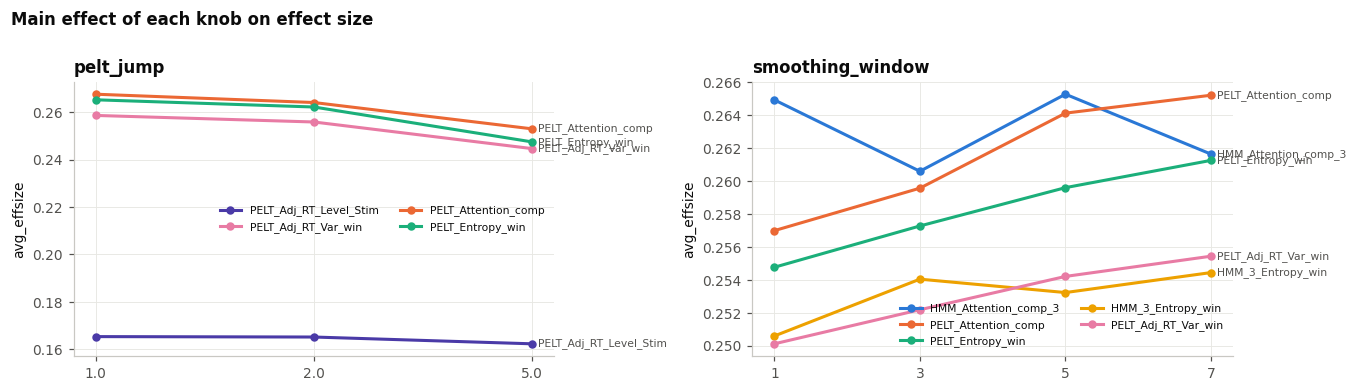

Pooled across methods (mean effect size by level):

--- pelt_jump ---
               avg_effsize  avg_sig%  avg_corr_sig%
cfg_pelt_jump                                      
1.0                 0.2392   86.3785        79.9020
2.0                 0.2368   86.3013        79.3428
5.0                 0.2268   85.2127        77.5199

--- smoothing_window ---
                      avg_effsize  avg_sig%  avg_corr_sig%
cfg_smoothing_window                                      
1                          0.2087   83.9008        75.2323
3                          0.2084   84.0155        77.3897
5                          0.2078   84.0283        79.0620
7                          0.2062   83.7577        77.0782


In [6]:
# [cell 9]
meths = topn_methods(5)          # controls every panel EXCEPT pelt_jump
PELT_METHS = sorted(m for m in df["method"].unique() if m.startswith("PELT"))

# pelt_jump only reaches the PELT family, so that panel shows ALL PELT methods
# regardless of rank (PELT_Adj_RT_Level_Stim is well outside the top N but its jump
# response is still the thing the knob is being judged on). Every other knob
# shows the top-N methods.
PANEL_METHS = {"cfg_pelt_jump": PELT_METHS}

# one colour per method across all panels, so a series keeps its colour
_all = list(dict.fromkeys(list(meths) + PELT_METHS))
COLOR = {m: SERIES[i % len(SERIES)] for i, m in enumerate(_all)}

n = len(VARY)
ncol = 2; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(6.2 * ncol, 3.5 * nrow), squeeze=False)

for ax, k in zip(axes.ravel(), VARY):
    for m in PANEL_METHS.get(k, meths):
        s = (df[df.method == m].groupby(k)[EFF].mean().sort_index())
        if s.empty:
            continue
        ax.plot(s.index.astype(str), s.values, marker="o", ms=4.5, lw=2,
                color=COLOR[m], label=m)
        ax.annotate(m, (len(s) - 1, s.values[-1]), textcoords="offset points",
                    xytext=(4, 0), fontsize=7, color=MUTED, va="center")
    ax.set_title(k.replace("cfg_", ""), fontweight="bold", loc="left")
    ax.set_xlabel(""); ax.set_ylabel(EFF)
    ax.legend(fontsize=7, ncol=2, loc="best")
for ax in axes.ravel()[n:]:
    ax.axis("off")
fig.suptitle("Main effect of each knob on effect size", fontweight="bold", x=0.01,
             ha="left", y=1.0)
plt.tight_layout(); plt.show()

print("Pooled across methods (mean effect size by level):")
for k in VARY:
    t = df.groupby(k)[[EFF, SIG, CORR]].mean().round(4)
    print(f"\n--- {k.replace('cfg_','')} ---"); print(t.to_string())

*[cell 10]*

## 3. The winner

Ranked by effect size, with **both** significance rates shown. See section 4
before trusting the top row.

In [7]:
# [cell 11]
keep = [c for c in [EFF, SIG, CORR, "blocks_mean", "n_validatable", "n_obs"]
        if c in df.columns]

best_cfg = (df.groupby(["method"] + VARY, dropna=False)[keep].mean().reset_index()
              .sort_values(EFF, ascending=False).reset_index(drop=True))
print("TOP 20 method x config by effect size:")
display(best_cfg.head(20).round(4))

print("\nBest config for each method:")
display(best_cfg.sort_values(EFF, ascending=False)
                .groupby("method", as_index=False).first()
                .sort_values(EFF, ascending=False).round(4))

print("\nMethod ranking (averaged over all configs):")
display(df.groupby("method")[keep].mean().sort_values(EFF, ascending=False).round(4))

TOP 20 method x config by effect size:


,method,cfg_pelt_jump,cfg_smoothing_window,avg_effsize,avg_sig%,avg_corr_sig%,blocks_mean,n_validatable,n_obs
0,PELT_Attention_comp,1.0,7,0.2704,89.5062,88.8480,3.9154,270.0,272.0
1,PELT_Attention_comp,1.0,5,0.2694,90.2107,89.2157,3.8603,269.0,272.0
2,PELT_Attention_comp,2.0,7,0.2678,89.7531,89.0931,3.8824,270.0,272.0
3,PELT_Attention_comp,2.0,5,0.2671,89.5911,88.6029,3.8419,269.0,272.0
4,PELT_Entropy_win,1.0,7,0.2670,86.8389,86.5196,4.6140,271.0,272.0
5,PELT_Entropy_win,1.0,5,0.2662,86.7159,86.3971,4.5846,271.0,272.0
6,PELT_Attention_comp,1.0,3,0.2661,89.4672,88.4804,3.7684,269.0,272.0
7,HMM_Attention_comp_3,NaN,5,0.2653,87.2840,86.6422,5.4485,270.0,272.0
8,PELT_Entropy_win,2.0,7,0.2650,87.0849,86.7647,4.5809,271.0,272.0
9,HMM_Attention_comp_3,NaN,1,0.2649,87.4539,87.1324,5.3640,271.0,272.0



Best config for each method:


,method,cfg_pelt_jump,cfg_smoothing_window,avg_effsize,avg_sig%,avg_corr_sig%,blocks_mean,n_validatable,n_obs
14,PELT_Attention_comp,1.0,7,0.2704,89.5062,88.8480,3.9154,270.0,272.0
15,PELT_Entropy_win,1.0,7,0.2670,86.8389,86.5196,4.6140,271.0,272.0
11,HMM_Attention_comp_3,NaN,5,0.2653,87.2840,86.6422,5.4485,270.0,272.0
13,PELT_Adj_RT_Var_win,1.0,7,0.2601,82.9657,82.9657,4.7169,272.0,272.0
9,HMM_3_Entropy_win,NaN,7,0.2544,86.8873,86.8873,5.8382,272.0,272.0
8,HMM_3_Adj_RT_Var_win,NaN,7,0.2413,82.8431,82.8431,5.4191,272.0,272.0
6,HMM_2_Entropy_win,NaN,5,0.2380,85.4859,85.1716,4.6875,271.0,272.0
7,HMM_3_Adj_RT_Level_Stim,NaN,7,0.2183,89.9510,89.9510,5.0515,272.0,272.0
1,CPD_Adj_RT_Var_win,NaN,1,0.2099,80.1471,80.1471,4.3934,272.0,272.0
10,HMM_Attention_comp_2,NaN,3,0.2011,80.5031,78.4314,3.9081,265.0,272.0



Method ranking (averaged over all configs):


,avg_effsize,avg_sig%,avg_corr_sig%,blocks_mean,n_validatable,n_obs
method,,,,,,
HMM_Attention_comp_3,0.2631,87.1291,86.4890,5.4090,270.0000,272.0
PELT_Attention_comp,0.2615,89.1169,87.8370,3.7298,268.0833,272.0
PELT_Entropy_win,0.2582,86.2341,85.9171,4.4439,271.0000,272.0
HMM_3_Entropy_win,0.2531,86.8566,86.8566,5.7362,272.0000,272.0
PELT_Adj_RT_Var_win,0.2530,82.3814,81.9547,4.5196,270.5833,272.0
HMM_3_Adj_RT_Var_win,0.2405,83.4559,83.4559,5.3621,272.0000,272.0
HMM_2_Entropy_win,0.2357,85.2808,85.2022,4.6425,271.7500,272.0
HMM_Attention_comp_2,0.2001,80.5815,78.9522,3.8989,266.5000,272.0
HMM_2_Adj_RT_Var_win,0.1991,77.2579,75.9804,3.9963,267.5000,272.0


*[cell 12]*

## 4. Best solution per method

Each detector at the configuration maximising its effect size (precision) and at the configuration maximising
`avg_corr_sig%` (pervasiveness). A detector whose values barely move between the two tables has a configuration good
on both criteria.

Effect size is computed only on sessions with >= 2 blocks, so a method that often returns **one** block is scored on a
subset of sessions; `pct_single_block` = 1 - `n_validatable`/`n_obs` measures that. `Sig% - Corr%` is not an
independent tell: `Corr%` = `Sig%` x (`n_validatable`/`n_obs`). The flag below is a **diagnostic only**; it excludes
nothing from the winner.

`best_per_detector` (exported) is each detector's best configuration by η²_H over every configuration of the sweep;
the LVL1 notebook's H1 tests use these configurations for the T2 calibration rows.

In [8]:
# [cell 13]
SINGLE_BLOCK_MAX = 25   # % of sessions with <2 blocks above which the effect size is a subset estimate

FEAT = [c for c in df.columns if c.endswith("_effsize") and c != EFF_RAW]
FEAT_CORR = [c for c in df.columns if c.endswith("_corr_sig%") and c != CORR]

# one row per method x config, carrying the per-feature effect sizes as well
agg = (df.groupby(["method"] + VARY, dropna=False)[list(dict.fromkeys(keep + FEAT + FEAT_CORR))]
         .mean().reset_index())

# each method at ITS OWN best configuration
chk = (agg.sort_values(EFF, ascending=False, kind="stable").groupby("method", as_index=False).first()
          .set_index("method").sort_values(EFF, ascending=False))
chk["sig_minus_corr"] = chk[SIG] - chk[CORR]
chk["pct_single_block"] = 100 * (1 - chk["n_validatable"] / chk["n_obs"])
flag = chk["pct_single_block"] > SINGLE_BLOCK_MAX

# same table, optimized for pervasiveness instead of precision
chk_sig = (agg.sort_values(CORR, ascending=False, kind="stable").groupby("method", as_index=False).first()
              .set_index("method").sort_values(CORR, ascending=False))
chk_sig["pct_single_block"] = 100 * (1 - chk_sig["n_validatable"] / chk_sig["n_obs"])

_cols = [EFF, SIG, CORR, "blocks_mean", "pct_single_block"] + VARY
_star = lambda t: np.where(np.arange(len(t)) == 0, "★", "")
print(f"optimized for {EFF_LABEL}:")
display(chk[_cols].assign(**{"SUBSET?": np.where(flag, "<-- partial coverage", ""),
                             "BEST": _star(chk)}).round(3))
print(f"optimized for {CORR}:")
display(chk_sig[_cols].assign(**{"BEST": _star(chk_sig)}).round(3))

if flag.any():
    print(f"PARTIAL COVERAGE (pct_single_block > {SINGLE_BLOCK_MAX}%):",
          ", ".join(f"{m} ({chk.loc[m, 'pct_single_block']:.1f}%)" for m in chk.index[flag]))
else:
    print(f"Every method splits at least {100 - SINGLE_BLOCK_MAX}% of sessions.")

# Each detector's best configuration (highest η²_H over every configuration of the sweep): the LVL1 notebook's H1
# tests read the T2 calibration sessions of these configurations. The quality gates (section 0) must not exclude any
# of them, or the gated ranking above and this table would describe different configurations.
BEST = _best_eta.reset_index()[["method", "cfg_file", "cfg_smoothing_window", "cfg_pelt_jump", "η²_H", "Corr%",
                                "blocks_mean", "n_validatable", "n_obs"]]
_gated = set(zip(df.method, df.cfg_smoothing_window.astype(float), df.cfg_pelt_jump.astype(float).fillna(-1)))
_out = [r.method for r in BEST.itertuples()
        if (r.method, float(r.cfg_smoothing_window), -1.0 if pd.isna(r.cfg_pelt_jump) else float(r.cfg_pelt_jump))
        not in _gated]
if _out:
    raise SystemExit(f"the quality gates (section 0) exclude the best configuration of {_out}; decide whether the "
                     "gates or the configurations should change")
export("best_per_detector", BEST)
# the gated per-configuration table and each detector's best configuration by each criterion, with its sweep file: the
# LVL1 calibration figure (make_replication_figures) and the LVL1 notebook's Corr% figure test read them
_cf = cfg1[["method", "cfg_smoothing_window", "cfg_pelt_jump", "cfg_file"]]
_with_file = lambda t: t.merge(_cf, on=["method", "cfg_smoothing_window", "cfg_pelt_jump"], how="left")
export("configs", _with_file(agg))
export("best_eta", _with_file(chk.reset_index()))
export("best_corr", _with_file(chk_sig.reset_index()))


optimized for avg η²_H:


,avg_effsize,avg_sig%,avg_corr_sig%,blocks_mean,pct_single_block,cfg_pelt_jump,cfg_smoothing_window,SUBSET?,BEST
method,,,,,,,,,
PELT_Attention_comp,0.270,89.506,88.848,3.915,0.735,1.0,7,,★
PELT_Entropy_win,0.267,86.839,86.520,4.614,0.368,1.0,7,,
HMM_Attention_comp_3,0.265,87.284,86.642,5.449,0.735,NaN,5,,
PELT_Adj_RT_Var_win,0.260,82.966,82.966,4.717,0.000,1.0,7,,
HMM_3_Entropy_win,0.254,86.887,86.887,5.838,0.000,NaN,7,,
HMM_3_Adj_RT_Var_win,0.241,82.843,82.843,5.419,0.000,NaN,7,,
HMM_2_Entropy_win,0.238,85.486,85.172,4.688,0.368,NaN,5,,
HMM_3_Adj_RT_Level_Stim,0.218,89.951,89.951,5.051,0.000,NaN,7,,
CPD_Adj_RT_Var_win,0.210,80.147,80.147,4.393,0.000,NaN,1,,


optimized for avg_corr_sig%:


,avg_effsize,avg_sig%,avg_corr_sig%,blocks_mean,pct_single_block,cfg_pelt_jump,cfg_smoothing_window,BEST
method,,,,,,,,
HMM_3_Adj_RT_Level_Stim,0.218,89.951,89.951,5.051,0.000,NaN,7,★
PELT_Attention_comp,0.269,90.211,89.216,3.860,1.103,1.0,5,
HMM_2_Adj_RT_Level_Stim,0.199,90.226,88.235,4.357,2.206,NaN,7,
HMM_Attention_comp_3,0.265,87.454,87.132,5.364,0.368,NaN,1,
HMM_3_Entropy_win,0.251,87.010,87.010,5.526,0.000,NaN,1,
PELT_Entropy_win,0.265,87.085,86.765,4.581,0.368,2.0,7,
HMM_2_Entropy_win,0.237,85.539,85.539,4.640,0.000,NaN,7,
HMM_3_Adj_RT_Var_win,0.239,83.946,83.946,5.309,0.000,NaN,3,
PELT_Adj_RT_Var_win,0.257,83.211,83.211,4.636,0.000,2.0,5,


PARTIAL COVERAGE (pct_single_block > 25%): CPD_Adj_RT_Level_Stim (25.4%)


,method,cfg_file,cfg_smoothing_window,cfg_pelt_jump,η²_H,Corr%,blocks_mean,n_validatable,n_obs
0,CPD_Adj_RT_Level_Stim,cfg000000.csv,1,NaN,0.140700,61.642157,2.183824,203,272
1,CPD_Adj_RT_Var_win,cfg000000.csv,1,NaN,0.209908,80.147059,4.393382,272,272
2,CPD_Attention_comp,cfg000000.csv,1,NaN,0.179419,74.387255,2.742647,234,272
3,CPD_Entropy_win,cfg000000.csv,1,NaN,0.173745,75.980392,3.547794,262,272
4,HMM_2_Adj_RT_Level_Stim,cfg000003.csv,7,NaN,0.199448,88.235294,4.356618,266,272
5,HMM_2_Adj_RT_Var_win,cfg000002.csv,5,NaN,0.200438,76.715686,4.022059,268,272
6,HMM_2_Entropy_win,cfg000002.csv,5,NaN,0.238042,85.171569,4.687500,271,272
7,HMM_3_Adj_RT_Level_Stim,cfg000003.csv,7,NaN,0.218289,89.950980,5.051471,272,272
8,HMM_3_Adj_RT_Var_win,cfg000003.csv,7,NaN,0.241312,82.843137,5.419118,272,272
9,HMM_3_Entropy_win,cfg000003.csv,7,NaN,0.254449,86.887255,5.838235,272,272


,method,cfg_pelt_jump,cfg_smoothing_window,avg_effsize,avg_sig%,avg_corr_sig%,blocks_mean,n_validatable,n_obs,Adj RT Level (Stim)_effsize,Adj RT Var (win)_effsize,Entropy (win)_effsize,Adj RT Level (Stim)_corr_sig%,Adj RT Var (win)_corr_sig%,Entropy (win)_corr_sig%,cfg_file
0,CPD_Adj_RT_Level_Stim,NaN,1,0.140700,82.594417,61.642157,2.183824,203.0,272.0,0.106430,0.161415,0.154255,74.632353,55.147059,55.147059,cfg000000.csv
1,CPD_Adj_RT_Level_Stim,NaN,3,0.139552,83.006536,62.254902,2.150735,204.0,272.0,0.108179,0.157526,0.152951,75.000000,56.985294,54.779412,cfg000001.csv
2,CPD_Adj_RT_Level_Stim,NaN,5,0.136650,82.735043,59.313725,2.036765,195.0,272.0,0.106634,0.155730,0.147585,71.691176,53.676471,52.573529,cfg000002.csv
3,CPD_Adj_RT_Level_Stim,NaN,7,0.126246,81.684982,54.656863,1.882353,182.0,272.0,0.098697,0.142057,0.137984,66.911765,47.058824,50.000000,cfg000003.csv
4,CPD_Adj_RT_Var_win,NaN,1,0.209908,80.147059,80.147059,4.393382,272.0,272.0,0.073045,0.343611,0.213068,50.000000,100.000000,90.441176,cfg000000.csv
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,PELT_Entropy_win,2.0,7,0.265042,87.084871,86.764706,4.580882,271.0,272.0,0.092284,0.258602,0.444239,67.279412,93.382353,99.632353,cfg000007.csv
92,PELT_Entropy_win,5.0,1,0.243635,85.116851,84.803922,4.176471,271.0,272.0,0.088020,0.235666,0.407220,64.338235,90.441176,99.632353,cfg000008.csv
93,PELT_Entropy_win,5.0,3,0.245831,84.993850,84.681373,4.242647,271.0,272.0,0.088529,0.237915,0.411049,63.602941,90.808824,99.632353,cfg000009.csv
94,PELT_Entropy_win,5.0,5,0.248418,85.239852,84.926471,4.316176,271.0,272.0,0.089312,0.241506,0.414437,63.602941,91.544118,99.632353,cfg000010.csv


,method,cfg_pelt_jump,cfg_smoothing_window,avg_effsize,avg_sig%,avg_corr_sig%,blocks_mean,n_validatable,n_obs,Adj RT Level (Stim)_effsize,Adj RT Var (win)_effsize,Entropy (win)_effsize,Adj RT Level (Stim)_corr_sig%,Adj RT Var (win)_corr_sig%,Entropy (win)_corr_sig%,sig_minus_corr,pct_single_block,cfg_file
0,PELT_Attention_comp,1.0,7,0.270403,89.506173,88.848039,3.915441,270.0,272.0,0.101740,0.374673,0.334797,72.794118,97.426471,96.323529,0.658134,0.735294,cfg000003.csv
1,PELT_Entropy_win,1.0,7,0.267019,86.838868,86.519608,4.613971,271.0,272.0,0.092711,0.259403,0.448944,66.176471,93.750000,99.632353,0.319261,0.367647,cfg000003.csv
2,HMM_Attention_comp_3,NaN,5,0.265283,87.283951,86.642157,5.448529,270.0,272.0,0.093246,0.361334,0.341268,63.970588,97.426471,98.529412,0.641794,0.735294,cfg000002.csv
3,PELT_Adj_RT_Var_win,1.0,7,0.260070,82.965686,82.965686,4.716912,272.0,272.0,0.076990,0.478453,0.224769,55.882353,100.000000,93.014706,0.000000,0.000000,cfg000003.csv
4,HMM_3_Entropy_win,NaN,7,0.254449,86.887255,86.887255,5.838235,272.0,272.0,0.090583,0.302595,0.370168,64.338235,97.426471,98.897059,0.000000,0.000000,cfg000003.csv
5,HMM_3_Adj_RT_Var_win,NaN,7,0.241312,82.843137,82.843137,5.419118,272.0,272.0,0.082905,0.399180,0.241851,55.514706,98.529412,94.485294,0.000000,0.000000,cfg000003.csv
6,HMM_2_Entropy_win,NaN,5,0.238042,85.485855,85.171569,4.687500,271.0,272.0,0.086000,0.255764,0.372361,63.970588,92.279412,99.264706,0.314286,0.367647,cfg000002.csv
7,HMM_3_Adj_RT_Level_Stim,NaN,7,0.218289,89.950980,89.950980,5.051471,272.0,272.0,0.116910,0.279046,0.258910,79.411765,95.220588,95.220588,0.000000,0.000000,cfg000003.csv
8,CPD_Adj_RT_Var_win,NaN,1,0.209908,80.147059,80.147059,4.393382,272.0,272.0,0.073045,0.343611,0.213068,50.000000,100.000000,90.441176,0.000000,0.000000,cfg000000.csv
9,HMM_Attention_comp_2,NaN,3,0.201054,80.503145,78.431373,3.908088,265.0,272.0,0.074128,0.285197,0.243838,58.088235,88.602941,88.602941,2.071772,2.573529,cfg000001.csv


,method,cfg_pelt_jump,cfg_smoothing_window,avg_effsize,avg_sig%,avg_corr_sig%,blocks_mean,n_validatable,n_obs,Adj RT Level (Stim)_effsize,Adj RT Var (win)_effsize,Entropy (win)_effsize,Adj RT Level (Stim)_corr_sig%,Adj RT Var (win)_corr_sig%,Entropy (win)_corr_sig%,pct_single_block,cfg_file
0,HMM_3_Adj_RT_Level_Stim,NaN,7,0.218289,89.950980,89.950980,5.051471,272.0,272.0,0.116910,0.279046,0.258910,79.411765,95.220588,95.220588,0.000000,cfg000003.csv
1,PELT_Attention_comp,1.0,5,0.269428,90.210657,89.215686,3.860294,269.0,272.0,0.101996,0.373973,0.332316,74.264706,97.426471,95.955882,1.102941,cfg000002.csv
2,HMM_2_Adj_RT_Level_Stim,NaN,7,0.199448,90.225564,88.235294,4.356618,266.0,272.0,0.114118,0.244430,0.239796,82.720588,91.544118,90.441176,2.205882,cfg000003.csv
3,HMM_Attention_comp_3,NaN,1,0.264939,87.453875,87.132353,5.363971,271.0,272.0,0.092976,0.363316,0.338523,65.441176,97.058824,98.897059,0.367647,cfg000000.csv
4,HMM_3_Entropy_win,NaN,1,0.250596,87.009804,87.009804,5.525735,272.0,272.0,0.090403,0.286309,0.375076,65.808824,96.323529,98.897059,0.000000,cfg000000.csv
5,PELT_Entropy_win,2.0,7,0.265042,87.084871,86.764706,4.580882,271.0,272.0,0.092284,0.258602,0.444239,67.279412,93.382353,99.632353,0.367647,cfg000007.csv
6,HMM_2_Entropy_win,NaN,7,0.237412,85.539216,85.539216,4.639706,272.0,272.0,0.085987,0.255682,0.370567,65.073529,91.911765,99.632353,0.000000,cfg000003.csv
7,HMM_3_Adj_RT_Var_win,NaN,3,0.239182,83.946078,83.946078,5.308824,272.0,272.0,0.083581,0.394399,0.239566,58.088235,99.264706,94.485294,0.000000,cfg000001.csv
8,PELT_Adj_RT_Var_win,2.0,5,0.257180,83.210784,83.210784,4.636029,272.0,272.0,0.075832,0.472336,0.223372,56.617647,99.632353,93.382353,0.000000,cfg000006.csv
9,CPD_Adj_RT_Var_win,NaN,1,0.209908,80.147059,80.147059,4.393382,272.0,272.0,0.073045,0.343611,0.213068,50.000000,100.000000,90.441176,0.000000,cfg000000.csv


*[cell 20]*

## 6. Interactions

- **`pelt_jump` x `smoothing_window`** - the current sweep. Mean over PELT methods only
  (pelt_jump is NaN elsewhere). The other panels are skipped when their knobs are fixed.

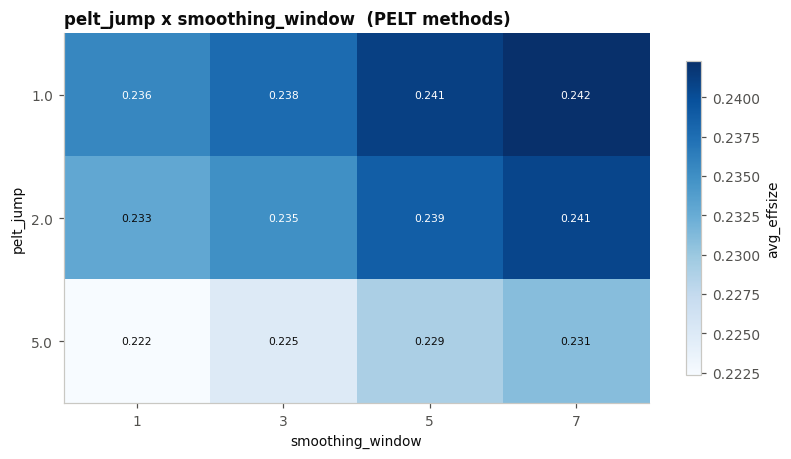

cfg_smoothing_window,1,3,5,7
cfg_pelt_jump,,,,
1.0,0.2356,0.2377,0.2410,0.2423
2.0,0.2329,0.2349,0.2388,0.2406
5.0,0.2223,0.2249,0.2290,0.2310


skip min_block_size x pelt_jump: not varied
skip derivative_filter_size x mad_window_size: not varied


In [9]:
# [cell 21]
def heat(a, b, title):
    ca, cb = f"cfg_{a}", f"cfg_{b}"
    if ca not in df.columns or cb not in df.columns:
        print(f"skip {a} x {b}: not in results"); return
    if df[ca].nunique() < 2 or df[cb].nunique() < 2:
        print(f"skip {a} x {b}: not varied"); return
    piv = df.pivot_table(index=ca, columns=cb, values=EFF, aggfunc="mean")
    fig, ax = plt.subplots(figsize=(1.0 * len(piv.columns) + 3.4,
                                    0.55 * len(piv.index) + 2.6))
    im = ax.imshow(piv.values, cmap="Blues", aspect="auto")   # sequential, one hue
    ax.set_xticks(range(len(piv.columns)), piv.columns)
    ax.set_yticks(range(len(piv.index)), piv.index)
    ax.set_xlabel(b); ax.set_ylabel(a)
    ax.set_title(title, fontweight="bold", loc="left")
    ax.grid(False)
    for i in range(piv.shape[0]):                              # values on cells
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7,
                    color="white" if v > np.nanmean(piv.values) else INK)
    fig.colorbar(im, ax=ax, label=EFF, shrink=0.85)
    plt.tight_layout(); plt.show()
    display(piv.round(4))

heat("pelt_jump", "smoothing_window", "pelt_jump x smoothing_window  (PELT methods)")
heat("min_block_size", "pelt_jump", "min_block_size x pelt_jump")
heat("derivative_filter_size", "mad_window_size",
     "derivative_filter_size x mad_window_size")

*[cell 22]*

## 7. Summary

The winner under each optimisation target, with its configuration, and the selection written for the LVL1 notebook.

In [10]:
# [cell 23]
def report_winner(tbl, criterion, label):
    win = tbl.index[0]
    row = tbl.loc[win]
    print("=" * 72)
    print(f"WINNER by {label}: {win}")
    print("=" * 72)
    print(f"  {EFF_LABEL:16} {row[EFF]:.4f}")
    print(f"  {SIG:16} {row[SIG]:.1f}%")
    print(f"  {CORR:16} {row[CORR]:.1f}%")
    print(f"  blocks_mean      {row['blocks_mean']:.2f}")
    print(f"  pct_single_block {row['pct_single_block']:.1f}%")
    print()
    print("  best configuration:")
    knobs = {}
    for k in VARY:
        if k == "cfg_pelt_jump" and pd.isna(row[k]):
            # PELT rows at the winner's value of every OTHER varied knob (smoothing_window,
            # rt_threshold_na_handling, ...), so the jump is not averaged across them.
            _p = df[df["method"].str.startswith("PELT")]
            for _o in VARY:
                if _o != k and pd.notna(row[_o]):
                    _p = _p[_p[_o] == row[_o]]
            _j = _p.groupby(k)[criterion].mean().sort_values(ascending=False)
            _ru = _p.groupby("method")[criterion].mean().sort_values(ascending=False)
            print(f"    {k.replace('cfg_',''):28} = {_j.index[0]:g}   "
                  f"# runner-up @ the winner's other knobs ({_ru.index[0]}, {_ru.iloc[0]:.4f}); "
                  f"jumps {', '.join(f'{j:g}:{v:.4f}' for j, v in _j.items())}")
            knobs[k.replace("cfg_", "")] = _j.index[0]
        else:
            print(f"    {k.replace('cfg_',''):28} = {row[k]}")
            knobs[k.replace("cfg_", "")] = row[k]
    return win, knobs


w_eff, KNOBS_EFF = report_winner(chk, EFF, EFF_LABEL)
print()
w_sig, _ = report_winner(chk_sig, CORR, CORR)
print()
print("=" * 72)
if w_eff == w_sig:
    print(f"Both criteria agree on {w_eff}.")
else:
    print(f"Criteria disagree: {EFF_LABEL} -> {w_eff}, {CORR} -> {w_sig}.")
    print(f"  {w_eff:24} {EFF_LABEL} {chk.loc[w_eff, EFF]:.4f}   {CORR} {chk.loc[w_eff, CORR]:.1f}%")
    print(f"  {w_sig:24} {EFF_LABEL} {chk_sig.loc[w_sig, EFF]:.4f}   {CORR} {chk_sig.loc[w_sig, CORR]:.1f}%")
if w_eff != WINNER_LVL1:
    raise SystemExit(f"the gated winner {w_eff} is not the η²_H winner over every configuration ({WINNER_LVL1})")

# The selection the LVL1 notebook must use: the η²_H winner and the knob values of its best configuration. The LVL1
# notebook's calibration check compares LVL_1_CONFIG with this file. LVL_1_CONFIG_full = every key of the sweep
# script's LVL_1_CONFIG (the script copy, [cell 1]) with these knob values; script_copy = the copy's path.
_py = lambda v: int(v) if isinstance(v, (float, np.floating)) and float(v).is_integer() else (
    float(v) if isinstance(v, (float, np.floating)) else v)
SELECTION = {"sweep": SWEEP_DIR.name, "pipeline_fingerprint": SWEEP_PROV["pipeline_fingerprint"],
             "lvl0_input": SWEEP_PROV["lvl0_input"], "condition": SWEEP_PROV["condition"], "criterion": EFF,
             "detector": w_eff, "config": _best_eta.loc[w_eff, "cfg_file"].removesuffix(".csv"),
             "LVL_1_CONFIG": {k: _py(v) for k, v in KNOBS_EFF.items()}}
SELECTION["script_copy"] = str(SCRIPT_COPY)
SELECTION["LVL_1_CONFIG_full"] = {**SWEEP_LVL1_CONFIG, **SELECTION["LVL_1_CONFIG"]}
with open(LVL_OUTS / f"{SWEEP_DIR.name}_selection.json", "w") as _f:
    json.dump(SELECTION, _f, indent=2)
print(f"\nselection -> {LVL_OUTS / (SWEEP_DIR.name + '_selection.json')}")
print(json.dumps(SELECTION, indent=1))


WINNER by avg η²_H: PELT_Attention_comp
  avg η²_H         0.2704
  avg_sig%         89.5%
  avg_corr_sig%    88.8%
  blocks_mean      3.92
  pct_single_block 0.7%

  best configuration:
    pelt_jump                    = 1.0
    smoothing_window             = 7.0

WINNER by avg_corr_sig%: HMM_3_Adj_RT_Level_Stim
  avg η²_H         0.2183
  avg_sig%         90.0%
  avg_corr_sig%    90.0%
  blocks_mean      5.05
  pct_single_block 0.0%

  best configuration:
    pelt_jump                    = 1   # runner-up @ the winner's other knobs (PELT_Attention_comp, 88.8072); jumps 1:82.4142, 2:82.3223, 5:80.6985
    smoothing_window             = 7.0

Criteria disagree: avg η²_H -> PELT_Attention_comp, avg_corr_sig% -> HMM_3_Adj_RT_Level_Stim.
  PELT_Attention_comp      avg η²_H 0.2704   avg_corr_sig% 88.8%
  HMM_3_Adj_RT_Level_Stim  avg η²_H 0.2183   avg_corr_sig% 90.0%

selection -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs/_sweep_lvl1_T2_selection.json
{
 "swe